# Lab 9 — Gyroscope sensor parameters
Wheel diameter **5.6 cm** (r = 0.028 m) · base **L = B = 15.4 cm** · rotation run: **Option B** (closed loop, Lab 7 go-to-goal controller on the path "70" + one more lap of the "0": 9 turns ≥ 90°, the motor command saturates on the sharp turns of the 7).

Log `lab9_gyro.csv` from `lab9_gyro.qrs`, one line every ~10 ms, no header:
`t_us, gz_cal, encL, encR, phase` — `t_us` = `gyroscope[3]` (µs), `gz_cal` = `gyroscope[2]` (mdeg/s), encoders in degrees,
`phase`: 0 = warm-up (2 min, dropped), 1 = static (3 min), 2 = `traj`, 3 = rest (3 s), 4 = hand spin (30 s, robot spun by hand for §3).

Import of necessary libraries.

In [1]:
import numpy as np                                  # arrays
import matplotlib.pyplot as plt                     # plots
import pandas as pd                                 # tables
import os

In [2]:
r = 0.028                                           # wheel radius, m
B = 0.154                                           # base distance (L), m
enc_to_deg = 1.0                                    # encoder units -> degrees (TRIK encoders return degrees; change if you find ticks)
slip_mark_deg = None                                # <-- floor-mark (protractor) angle at the end, deg

LOG = 'lab9_gyro.csv'
if not os.path.exists(LOG):
    try:
        from google.colab import files
        up = files.upload()                         # any name is fine, e.g. cch4_lab9_gyro.csv
        LOG = [f for f in up if f.endswith('.csv') or f.endswith('.txt')][0]
    except ImportError:
        print('Put lab9_gyro.csv next to the notebook')
print('using log file:', LOG)

using log file: lab9_gyro.csv


## Load the log

In [3]:
data = np.loadtxt(LOG, delimiter=',')
restart = np.where(np.diff(data[:, 0]) < 0)[0]      # the program appends to the file: keep only the last run
if len(restart):
    data = data[restart[-1] + 1:]
data = data[data[:, 4] >= 0.5]                      # drop the warm-up (phase 0)
t_us, gz, encL, encR, phase = data.T
phase = np.round(phase).astype(int)
# gyroscope[3] ticks: the static phase lasts exactly 180 s on the program clock -> find the tick length
st_ticks = t_us[phase == 1][-1] - t_us[phase == 1][0]
tick_us = 180e6 / st_ticks
tick_us = 256.0 if abs(tick_us - 256) < 5 else (1.0 if abs(tick_us - 1) < 0.05 else tick_us)
print(f'one gyroscope[3] tick = {tick_us:g} us')
t = (t_us - t_us[0]) * tick_us / 1e6                # s
w = gz / 1000                                       # rate, deg/s
theta_enc = np.degrees(r / B * np.radians((encR - encL) * enc_to_deg))   # encoder heading, deg (CCW +)

st = phase == 1                                     # static part
rot = (phase == 2) | (phase == 3)                   # trajectory run (+ rest at the end)
hand = phase == 4                                   # hand spin (only for the range test)
ts, ws = t[st] - t[st][0], w[st]
print(f'{len(t)} samples, mean dt = {np.mean(np.diff(t))*1000:.1f} ms, static {ts[-1]:.1f} s, rotation {t[rot][-1]-t[rot][0]:.1f} s')

def integrate(rate, time):                          # trapezoid rule with the real timestamps
    out = np.zeros(len(rate))
    out[1:] = np.cumsum((rate[1:] + rate[:-1]) / 2 * np.diff(time))
    return out

one gyroscope[3] tick = 256 us
2786 samples, mean dt = 89.1 ms, static 179.9 s, rotation 38.2 s


## §1. Offset (bias) `b_0`
Mean of the first 30 s of the static log, its standard error, and `b_0(T)` for T = 1, 2, 5, 10, 20, 30 s.

b0 (30 s) = 0.4476 deg/s,  standard error = 0.0041 deg/s


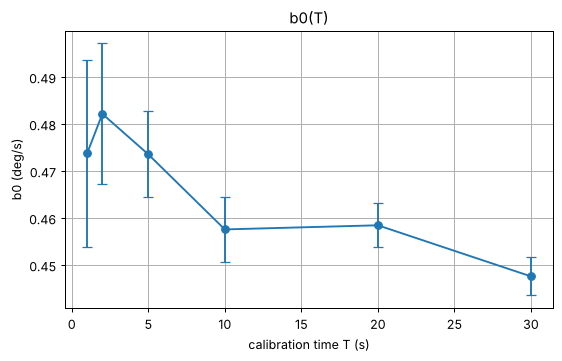

   T (s)  b0 (deg/s)  std. error (deg/s)
0      1      0.4737              0.0198
1      2      0.4822              0.0150
2      5      0.4736              0.0091
3     10      0.4576              0.0069
4     20      0.4585              0.0047
5     30      0.4476              0.0041

In [4]:
first30 = ws[ts <= 30]
b0_30 = np.mean(first30)
se_30 = np.std(first30) / np.sqrt(len(first30))
print(f'b0 (30 s) = {b0_30:.4f} deg/s,  standard error = {se_30:.4f} deg/s')

T_list = [1, 2, 5, 10, 20, 30]
b0_T = [np.mean(ws[ts <= T]) for T in T_list]
se_T = [np.std(ws[ts <= T]) / np.sqrt(np.sum(ts <= T)) for T in T_list]
plt.figure(figsize=(7, 4))
plt.errorbar(T_list, b0_T, yerr=se_T, fmt='o-', capsize=4)
plt.xlabel('calibration time T (s)'); plt.ylabel('b0 (deg/s)'); plt.title('b0(T)'); plt.grid(True)
plt.show()
pd.DataFrame({'T (s)': T_list, 'b0 (deg/s)': b0_T, 'std. error (deg/s)': se_T}).round(4)

**My calibration method `calibrate_gyro(log)`**: take the first `T_cal` seconds of the static log, throw away outliers
(samples more than 3·MAD from the median), and return the mean of the rest. `T_cal` is chosen where the `b_0(T)` curve becomes flat.

In [5]:
T_cal = 10                                          # s, chosen from the b0(T) plot

def calibrate_gyro(log, T=T_cal):
    tt = (log[:, 0] - log[0, 0]) / 1e6
    rate = log[:, 1][tt <= T] / 1000                # deg/s
    med = np.median(rate)
    mad = np.median(np.abs(rate - med)) + 1e-9
    good = np.abs(rate - med) < 3 * 1.4826 * mad    # outlier rejection
    return np.mean(rate[good])

b0 = calibrate_gyro(data[st])
print(f'calibrate_gyro: b0 = {b0:.4f} deg/s  (T = {T_cal} s)')

theta_gyro_rot = integrate(w[rot] - b0, t[rot])
e_end = theta_gyro_rot[-1] - (theta_enc[rot][-1] - theta_enc[rot][0])
print(f'heading error left at the end of the rotation run (gyro - encoder): {e_end:.2f} deg')

calibrate_gyro: b0 = 0.4315 deg/s  (T = 10 s)
heading error left at the end of the rotation run (gyro - encoder): 55.47 deg


## §2. Bias drift `d`
30-s window means → line fit → `d`. Heading from (a) the raw rate and (b) the rate minus `b_0`.

bias drift d = -0.01286 deg/s/min
(a) uncorrected heading drift = 25.68 deg/min,  check b0*60 = 26.86 deg/min
(b) residual heading error after 1 min: 1.00 deg
(b) residual heading error after 2 min: 0.11 deg
(b) residual heading error after 3 min: 0.11 deg


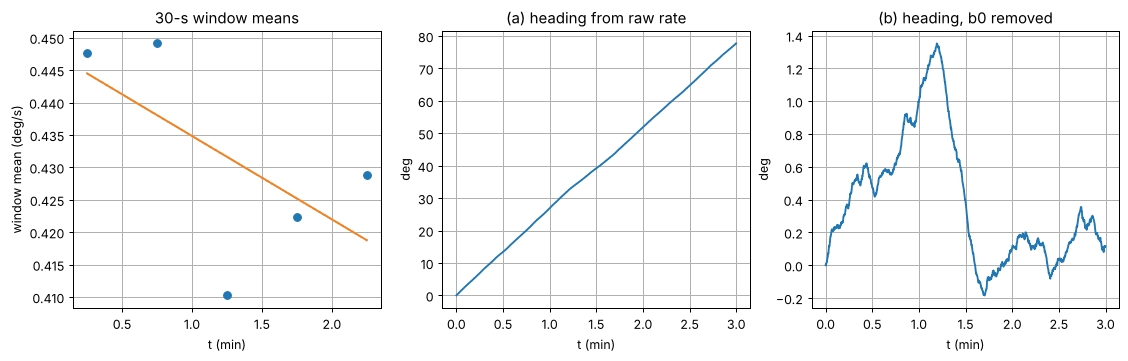

In [6]:
win = 30
centers, means = [], []
for k in range(int(ts[-1] // win)):
    s = (ts >= k * win) & (ts < (k + 1) * win)
    centers.append((k + 0.5) * win / 60); means.append(np.mean(ws[s]))
d, c0 = np.polyfit(centers, means, 1)               # deg/s per min
print(f'bias drift d = {d:.5f} deg/s/min')

theta_a = integrate(ws, ts)                         # (a) raw
theta_b = integrate(ws - b0, ts)                    # (b) bias corrected
slope_a = np.polyfit(ts / 60, theta_a, 1)[0]        # deg/min
print(f'(a) uncorrected heading drift = {slope_a:.2f} deg/min,  check b0*60 = {b0_30*60:.2f} deg/min')
for T in (60, 120, 180):
    print(f'(b) residual heading error after {T//60} min: {np.interp(T, ts, theta_b):.2f} deg')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(centers, means, 'o'); ax[0].plot(centers, np.polyval([d, c0], centers), '-')
ax[0].set_xlabel('t (min)'); ax[0].set_ylabel('window mean (deg/s)'); ax[0].set_title('30-s window means'); ax[0].grid(True)
ax[1].plot(ts / 60, theta_a); ax[1].set_xlabel('t (min)'); ax[1].set_ylabel('deg'); ax[1].set_title('(a) heading from raw rate'); ax[1].grid(True)
ax[2].plot(ts / 60, theta_b); ax[2].set_xlabel('t (min)'); ax[2].set_ylabel('deg'); ax[2].set_title('(b) heading, b0 removed'); ax[2].grid(True)
plt.show()

## Rotation run — gyro vs encoder (Step 3)

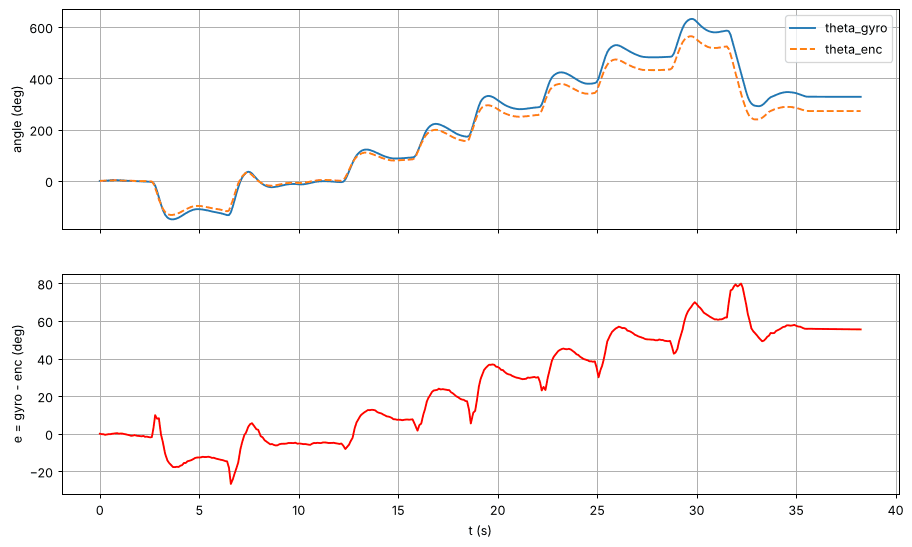

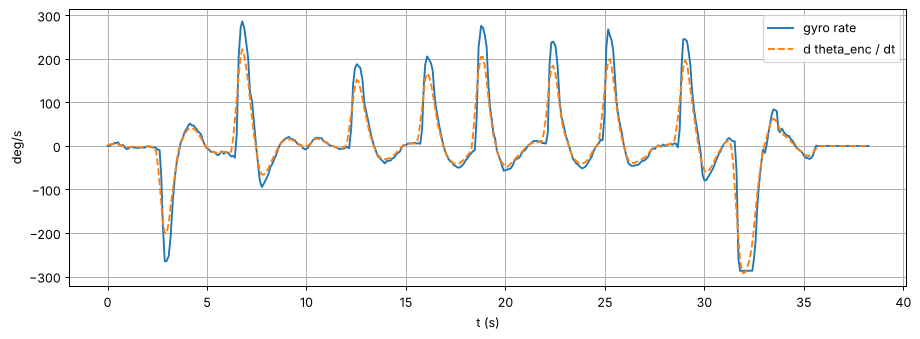

In [7]:
tr = t[rot] - t[rot][0]
w_rot = w[rot]
th_gyro = integrate(w_rot - b0, t[rot])             # gyro angle, deg
th_enc = theta_enc[rot] - theta_enc[rot][0]         # encoder angle, deg
e = th_gyro - th_enc

def smooth(v, n=5):
    return np.convolve(v, np.ones(n) / n, mode='same')
enc_rate = smooth(np.gradient(th_enc, t[rot]))      # encoder rate, deg/s

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(tr, th_gyro, label='theta_gyro'); ax[0].plot(tr, th_enc, '--', label='theta_enc')
ax[0].set_ylabel('angle (deg)'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(tr, e, 'r'); ax[1].set_ylabel('e = gyro - enc (deg)'); ax[1].set_xlabel('t (s)'); ax[1].grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(tr, w_rot - b0, label='gyro rate'); plt.plot(tr, enc_rate, '--', label='d theta_enc / dt')
plt.xlabel('t (s)'); plt.ylabel('deg/s'); plt.legend(); plt.grid(True); plt.show()

## §3. Measurement range `ω_max`
Gyro rate against encoder rate. A flat top (gyro stops following the encoders) means saturation.

largest reported rate (robot run + hand spin): +286.5 / -286.4 deg/s
samples at the top value: 1, at the bottom value: 7
The same extreme value repeats -> the gyro SATURATES at about +-286.5 deg/s


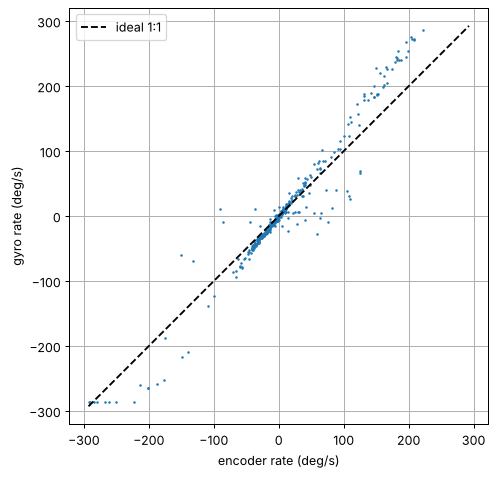

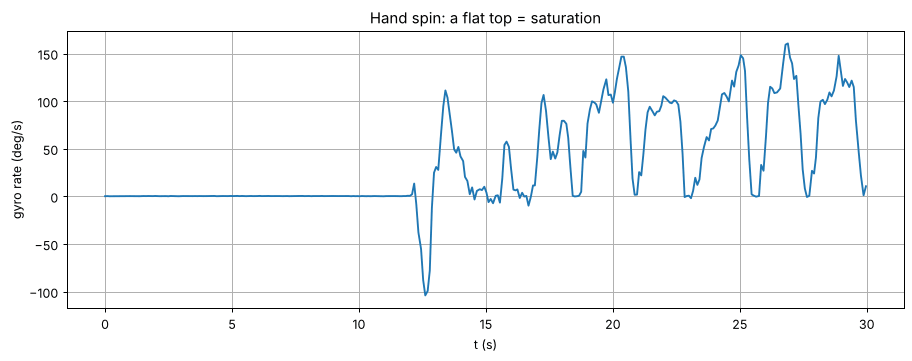

In [8]:
plt.figure(figsize=(6, 6))
plt.plot(enc_rate, w_rot - b0, '.', markersize=2)
lim = max(np.max(np.abs(enc_rate)), np.max(np.abs(w_rot - b0)))
plt.plot([-lim, lim], [-lim, lim], 'k--', label='ideal 1:1')
plt.xlabel('encoder rate (deg/s)'); plt.ylabel('gyro rate (deg/s)'); plt.legend(); plt.grid(True); plt.axis('equal')
plt.show()
# hand spin: the wheels do not measure this rotation, so only the gyro is plotted
if hand.any():
    plt.figure(figsize=(12, 4))
    plt.plot(t[hand] - t[hand][0], w[hand])
    plt.xlabel('t (s)'); plt.ylabel('gyro rate (deg/s)'); plt.title('Hand spin: a flat top = saturation'); plt.grid(True)
    plt.show()
w_all = w[rot | hand]
w_max_pos, w_max_neg = np.max(w_all), np.min(w_all)
print(f'largest reported rate (robot run + hand spin): +{w_max_pos:.1f} / {w_max_neg:.1f} deg/s')
print(f'samples at the top value: {np.sum(w_all >= w_max_pos - 1e-9)}, at the bottom value: {np.sum(w_all <= w_max_neg + 1e-9)}')
n_top, n_bot = np.sum(w_all >= w_max_pos - 1e-9), np.sum(w_all <= w_max_neg + 1e-9)
if max(n_top, n_bot) >= 3:
    print(f'The same extreme value repeats -> the gyro SATURATES at about +-{max(w_max_pos, -w_max_neg):.1f} deg/s')
else:
    print('No repeated extreme value -> no clear saturation: the range is at least these values.')

## §4. Resolution `Δ`

In [9]:
vals = np.unique(gz[st])                            # distinct raw values (mdeg/s)
steps = np.diff(vals)
small = steps[(steps > 0) & (steps < 1.5 * np.min(steps[steps > 0]))]
delta = np.mean(small) / 1000                       # deg/s (driver rounds the step to whole mdeg/s, so average the smallest steps)
print(f'{len(vals)} distinct values, smallest steps {np.unique(small)} mdeg/s -> Delta = {delta*1000:.2f} mdeg/s = {delta:.5f} deg/s')

57 distinct values, smallest steps [8. 9.] mdeg/s -> Delta = 8.76 mdeg/s = 0.00876 deg/s


## §5. Noise `σ`

sigma = 0.0757 deg/s  (R for Lab 12 at dt = 89.0 ms: R = sigma^2 = 0.005731 (deg/s)^2)
outliers > 4 sigma: 2 of 2023


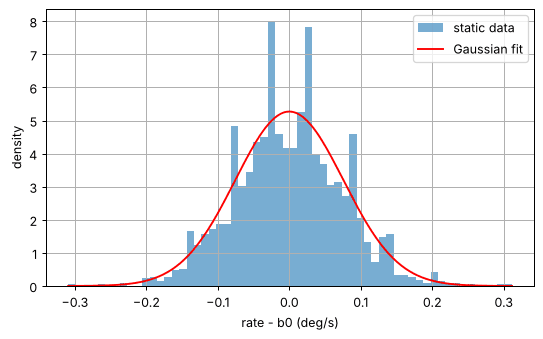

In [10]:
noise = ws - b0
sigma = np.std(noise)
print(f'sigma = {sigma:.4f} deg/s  (R for Lab 12 at dt = {np.mean(np.diff(ts))*1000:.1f} ms: R = sigma^2 = {sigma**2:.6f} (deg/s)^2)')
print(f'outliers > 4 sigma: {np.sum(np.abs(noise) > 4 * sigma)} of {len(noise)}')

plt.figure(figsize=(7, 4))
plt.hist(noise, bins=60, density=True, alpha=0.6, label='static data')
xg = np.linspace(noise.min(), noise.max(), 300)
plt.plot(xg, np.exp(-xg**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)), 'r', label='Gaussian fit')
plt.xlabel('rate - b0 (deg/s)'); plt.ylabel('density'); plt.legend(); plt.grid(True); plt.show()

## §6. Scale factor `s`
Sign check, raw → deg/s factor, and `s = Δθ_gyro/Δθ_enc - 1` fitted separately for CCW and CW, and for slow and sharp turns.

correlation gyro vs encoder rate = 0.971 -> positive gyro rate = CCW (same as encoder heading if CCW)
raw -> deg/s factor: 0.001 (read()[2] is in mdeg/s; readRawData() is not available from TRIK blocks)
s CCW = 12.02 %,  s CW = 8.93 %


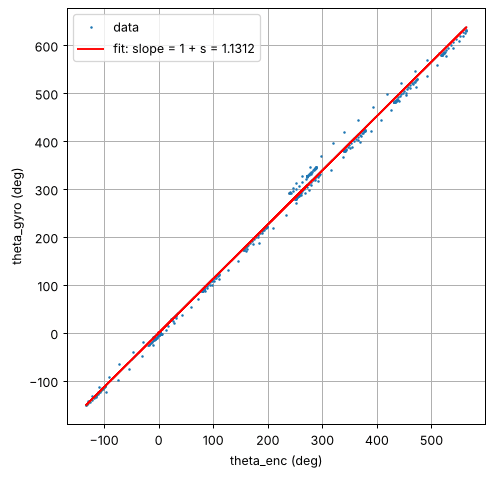

                              turns  s CCW (%)  s CW (%)
0    slow turns (|rate| < 32 deg/s)      14.14     15.15
1  sharp turns (|rate| >= 32 deg/s)      11.82      7.36

In [11]:
corr = np.corrcoef(w_rot - b0, enc_rate)[0, 1]
positive_dir = 'CCW' if corr > 0 else 'CW'
print(f'correlation gyro vs encoder rate = {corr:.3f} -> positive gyro rate = {positive_dir} (same as encoder heading if CCW)')

raw_factor = 0.001   # gyroscope[2] (= read()[2]) is already in mdeg/s, so 1 unit = 0.001 deg/s
print('raw -> deg/s factor:', raw_factor, '(read()[2] is in mdeg/s; readRawData() is not available from TRIK blocks)')

dg = np.diff(th_gyro); de = np.diff(th_enc)
mid_rate = enc_rate[1:]
def fit_s(mask):                                    # s = (sum of gyro angle increments) / (sum of encoder increments) - 1
    return np.sum(dg[mask]) / np.sum(de[mask]) - 1
ccw, cw = mid_rate > 5, mid_rate < -5
s_ccw, s_cw = fit_s(ccw), fit_s(cw)
print(f's CCW = {s_ccw*100:.2f} %,  s CW = {s_cw*100:.2f} %')

slope, icpt = np.polyfit(th_enc, th_gyro, 1)
plt.figure(figsize=(6, 6))
plt.plot(th_enc, th_gyro, '.', markersize=2, label='data')
plt.plot(th_enc, np.polyval([slope, icpt], th_enc), 'r', label=f'fit: slope = 1 + s = {slope:.4f}')
plt.xlabel('theta_enc (deg)'); plt.ylabel('theta_gyro (deg)'); plt.legend(); plt.grid(True); plt.show()

# s for slow and sharp turns (does s depend on the turning rate?)
turning = np.abs(mid_rate) > 5
lim_rate = np.median(np.abs(mid_rate[turning]))
rows = []
for name, blk in [(f'slow turns (|rate| < {lim_rate:.0f} deg/s)', np.abs(mid_rate) < lim_rate),
                  (f'sharp turns (|rate| >= {lim_rate:.0f} deg/s)', np.abs(mid_rate) >= lim_rate)]:
    rows.append({'turns': name, 's CCW (%)': fit_s(blk & ccw) * 100, 's CW (%)': fit_s(blk & cw) * 100})
pd.DataFrame(rows).round(2)

## Simulated gyro `gyro_sim(omega_true, t)`
`ω_meas = Q_Δ(sat_±ω_max[(1+s)ω_true + b_0 + d t + n])`, `n ~ N(0, σ^2)`

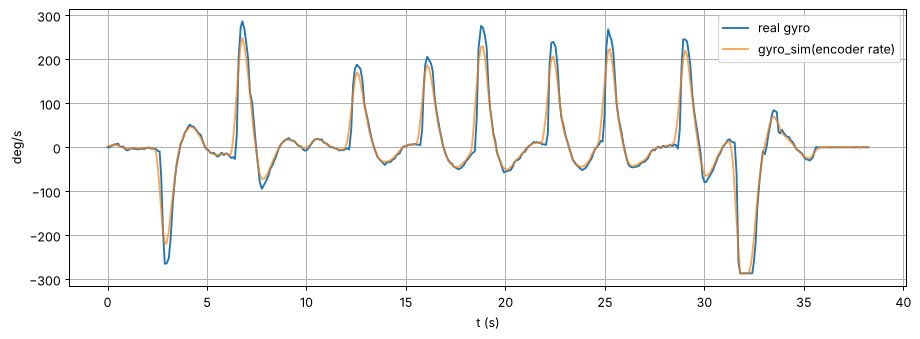

In [12]:
def gyro_sim(omega_true, t, seed=0):
    rng = np.random.default_rng(seed)
    omega_true = np.asarray(omega_true, dtype=float)
    s = np.where(omega_true >= 0, s_ccw, s_cw)     # scale-factor error (CCW / CW)
    out = (1 + s) * omega_true + b0 + d / 60 * t + rng.normal(0, sigma, len(t))   # d: deg/s per min -> per s
    out = np.clip(out, w_max_neg, w_max_pos)        # saturation
    return np.round(out / delta) * delta            # quantisation

w_sim = gyro_sim(enc_rate, tr)
plt.figure(figsize=(12, 4))
plt.plot(tr, w_rot, label='real gyro')
plt.plot(tr, w_sim, alpha=0.7, label='gyro_sim(encoder rate)')
plt.xlabel('t (s)'); plt.ylabel('deg/s'); plt.legend(); plt.grid(True); plt.show()

## Parameter table

In [13]:
table = pd.DataFrame([
    ['Offset (bias)', 'b0', b0, 'deg/s', f'static mean, outliers removed, T = {T_cal} s'],
    ['Bias drift', 'd', d, 'deg/s/min', '30-s window means'],
    ['Heading drift, uncorrected', '', slope_a, 'deg/min', 'slope of theta(t)'],
    ['Measurement range', '+-w_max', f'+{w_max_pos:.1f} / {w_max_neg:.1f}', 'deg/s', 'saturation test (robot run + hand spin)'],
    ['Resolution', 'Delta', delta, 'deg/s', 'quantisation step'],
    ['Noise std', 'sigma', sigma, 'deg/s', 'static, 3 min'],
    ['Raw -> deg/s factor', '', raw_factor, '-', 'read()[2] is mdeg/s'],
    ['Scale-factor error CCW / CW', 's', f'{s_ccw*100:.2f} / {s_cw*100:.2f}', '%', 'gyro vs encoder angle'],
    ['Positive rotation direction', '', positive_dir, '-', 'sign check'],
], columns=['Parameter', 'Symbol', 'Value', 'Unit', 'Method'])
table

                     Parameter  ...                                   Method
0                Offset (bias)  ...  static mean, outliers removed, T = 10 s
1                   Bias drift  ...                        30-s window means
2   Heading drift, uncorrected  ...                        slope of theta(t)
3            Measurement range  ...  saturation test (robot run + hand spin)
4                   Resolution  ...                        quantisation step
5                    Noise std  ...                            static, 3 min
6          Raw -> deg/s factor  ...                      read()[2] is mdeg/s
7  Scale-factor error CCW / CW  ...                    gyro vs encoder angle
8  Positive rotation direction  ...                               sign check

[9 rows x 5 columns]

Heading error from each source after 10 s, 1 min and 3 min (helps for the analysis).

In [14]:
rot_rate = np.mean(np.abs(enc_rate))                # typical turning rate in this run, deg/s
rows = []
for T in (10, 60, 180):
    rows.append({'time': f'{T} s',
                 'bias not removed: b0*T (deg)': abs(b0) * T,
                 'bias left after calibrate_gyro (deg)': abs(np.interp(T, ts, theta_b)),
                 'drift: d/60*T^2/2 (deg)': abs(d) / 60 * T**2 / 2,
                 'noise: sigma*sqrt(dt*T) (deg)': sigma * np.sqrt(np.mean(np.diff(ts)) * T),
                 'scale factor: |s|*rate*T (deg)': max(abs(s_ccw), abs(s_cw)) * rot_rate * T})
pd.DataFrame(rows).round(3)

    time  ...  scale factor: |s|*rate*T (deg)
0   10 s  ...                          54.036
1   60 s  ...                         324.215
2  180 s  ...                         972.646

[3 rows x 6 columns]

## Short analysis (≤ 1 page)
*Draft based on my run. Check it against your plots and add your floor-mark angle.*

**Data.** I used Option B: the go-to-goal path "70" plus one more lap of the "0". The gyro timestamp `read()[3]` counts in 256 µs ticks, not µs, and the logging loop ran at about 85–90 ms per sample.

**Parameters.**
- Bias b0 ≈ 0.43 deg/s. Without calibration this gives a heading drift of about 26 deg/min.
- The bias is stable: drift d ≈ −0.013 deg/s/min.
- Noise σ ≈ 0.076 deg/s, with a Gaussian-looking histogram.
- Resolution Δ ≈ 8.75 mdeg/s.
- The gyro saturates at ±286.4 deg/s. That is 32767 × 8.75 mdeg/s, the ±250 dps range of the sensor. The robot hits this limit by itself on its fastest turns: the flat bottom at t ≈ 32 s.
- The gyro reports about 9–12 % more rotation than the encoders (s CCW ≈ +12 %, s CW ≈ +9 %).

**Dominant error source.**
- After **10 s** of driving, the scale-factor error dominates. Every turn adds about 10 % of its angle, so the error e(t) jumps at every turn. The uncorrected bias would add only about 4°.
- After **1 min** and **3 min** of driving with turns, the scale factor still dominates. If the bias is not removed, it adds a steady 26 deg/min.
- With the robot standing still, only the bias matters, and the calibration removes almost all of it.
- Saturation adds an extra error only on the fastest turns.

Whether the +10 % is a real gyro error or an encoder error is decided by the floor-mark slip check. If r = 2.8 cm or B = 15.4 cm is a little off, or the wheels slip, the encoder angle is off too. Floor-mark angle: … deg.

**Calibration method.** `calibrate_gyro()` takes the median of the first 10 s of the static log, rejects samples more than 3·MAD away, and returns the mean of the rest. The b0(T) curve is flat to within about 0.02 deg/s after 10 s. With this b0, the residual heading error of the static log is about 1° after 1 min and about 0.1° after 3 min. So 10 s of standing still is enough.